In [21]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [22]:
import sys

sys.path.insert(1,"../src/")

In [23]:
import numpy as np
import scipy.io
import matplotlib.pyplot as plt
import scipy.signal as sp
import scipy.optimize as op

import acoustic_inversion as ai

from utilities import scramble_nums

In [24]:
# [Title, Freq, ssp, bdry, pos, beam, cint, rmax] = at.read_env("feif_scenario.env", "KRAKEN")

In [25]:
normize = lambda p: p/p.sum()

In [26]:
SAMPLING_FREQ = 2000
TRUE_SOUNDSPEED = 1460
TRUE_DENSITY = 1.3

In [27]:
# np.savez("../data/output/warping_arrival_times_corrected.npz", **data_warped)

In [54]:
# Organizing the extracted peaks into a dictionary
data = {
    "STFT":{**ai.peaks_from_file("../data/output/full_arrival_times_fromkraken.npz"),
            'freq_range':(225, 400)},
    "Warping":{**ai.peaks_from_file("../data/output/warping_arrival_times_fromkraken1.npz"),
            'freq_range':(220, 475)}
}

In [55]:
# Loading replicas of the arrival times
replicas = scipy.io.loadmat("../data/field_values20260921/field_values20260921.mat")

f = replicas['f'].squeeze()
f_Vg = f[1:-1]
c = replicas['soundspeed'].squeeze()
Vg = replicas['Vg'].squeeze().transpose([2,1,0,3])
#Vg = Vg[data_components['mode_nos'].squeeze()]
receiver_range = replicas['range'][0,0]*1e3
rho = replicas['rho'].squeeze()
# nmodes, nspeed, nfreq = Vg.shape

In [56]:
at_replica = receiver_range/Vg
at_reference = receiver_range/Vg[rho==TRUE_DENSITY,c==TRUE_SOUNDSPEED].squeeze()

In [61]:
replicas = {}
likelihood = {}
arrival_times = {}
arrival_times['reg_fixed'] = {}
for name in data:
    data[name]['fmask'] = (f_Vg >= data[name]['freq_range'][0]) &\
                          (f_Vg <= data[name]['freq_range'][1])
    data[name]['regression_f'] = f_Vg[data[name]['fmask']]

    data[name]['arrival_times'] =\
        ai.peaks_to_arrivaltimes(data[name]['peaks_coordinates'],
                                 deg = 2,
                                 freqs = data[name]['regression_f'],
                                 method = 'all',
                                 limit=np.inf)[0]
    
    

    replicas[name] = receiver_range/Vg[...,data[name]['mode_nos'],:]
    replicas[name] = replicas[name][...,data[name]['fmask']]
    likelihood[name] = {}
    likelihood[name]['combined'] = ai.likelihood_combined(data[name]['arrival_times'], replicas[name])
    likelihood[name]['direct'] = ai.likelihood_direct(data[name]['arrival_times'], replicas[name])

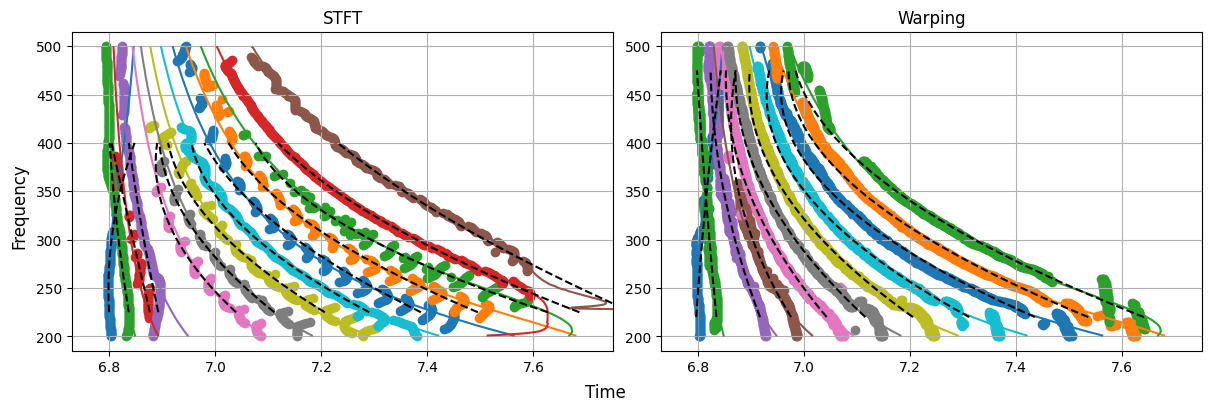

In [62]:
fig = plt.figure(layout="constrained")

for indfig, name in enumerate(data):
    ax = fig.add_subplot(1,2,indfig +1)
    for ind, p in enumerate(data[name]['peaks_coordinates']):
        mode_no = data[name]['mode_nos'][ind]
        color = f"C{mode_no}"
        ax.scatter(p[:,1], p[:,0], c=color)
        ax.plot(at_reference[mode_no], f_Vg, c=color)

    ax.set_xlim([6.73, 7.75])
    ax.plot(data[name]['arrival_times'].T, data[name]['regression_f'], 'k--')
    ax.grid()
    ax.set_title(name)
    

fig.supxlabel('Time')
fig.supylabel('Frequency')

fig.set_size_inches([12,4])

## Likelihoods

### Direct Likelihood

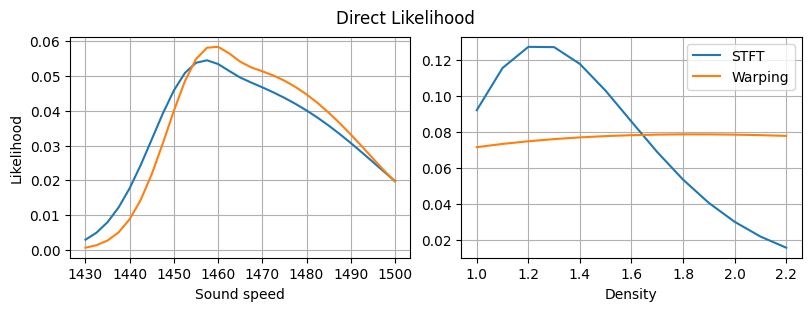

In [63]:
fig, (ax, ax_rho) = plt.subplots(1,2,layout="constrained")

for ind, name in enumerate(likelihood):
    ax.plot(c, normize(np.exp(likelihood[name]['direct'])).sum(0), label=name)
    
    ax_rho.plot(rho, normize(np.exp(likelihood[name]['direct'])).sum(1), label=name)
    
ax.grid()
ax.set_xlabel("Sound speed")
ax.set_ylabel("Likelihood")

ax_rho.grid()
ax_rho.set_xlabel("Density")

ax_rho.legend()

fig.suptitle('Direct Likelihood')
fig.set_size_inches([8,3])
    

### Combined Likelihood

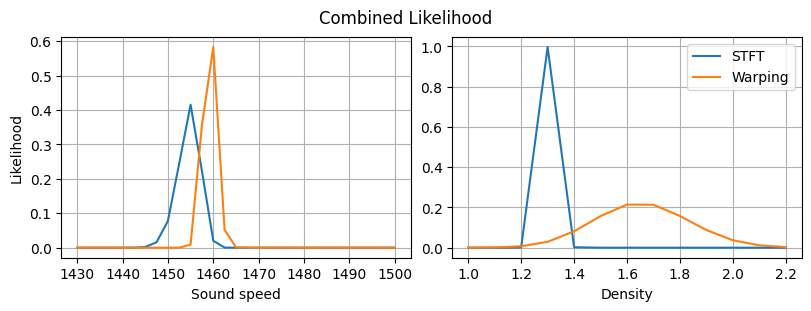

In [64]:
fig, (ax, ax_rho) = plt.subplots(1,2,layout="constrained")

for ind, name in enumerate(likelihood):
    ax.plot(c, normize(np.exp(likelihood[name]['combined'])).sum(0), label=name)
    
    ax_rho.plot(rho, normize(np.exp(likelihood[name]['combined'])).sum(1), label=name)
    
ax.grid()
ax.set_xlabel("Sound speed")
ax.set_ylabel("Likelihood")

ax_rho.grid()
ax_rho.set_xlabel("Density")

ax_rho.legend()

fig.suptitle('Combined Likelihood')
fig.set_size_inches([8,3])
    

### Joint Combined Likelihood

IndexError: index 2 is out of bounds for axis 0 with size 2

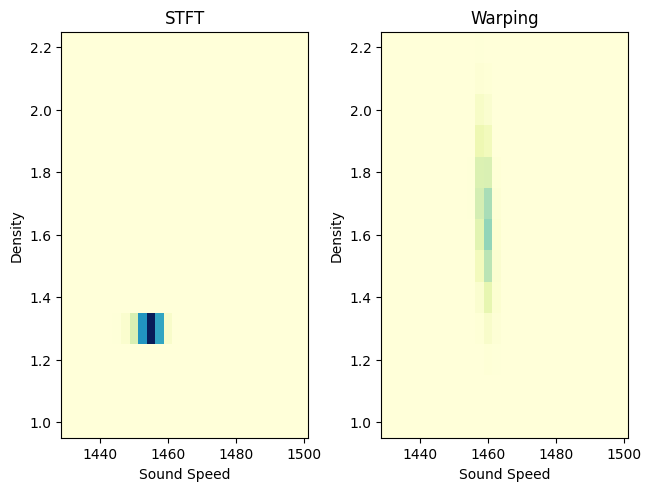

In [66]:
fig, ax = plt.subplots(1,2, layout="constrained")

vmin, vmax = (0, 0.4)
for ind, name in enumerate(likelihood):
    m1 = ax[ind].pcolormesh(c, rho,
                            normize(np.exp(likelihood[name]['combined'])),
                            vmin=vmin, vmax=vmax,
                            cmap="YlGnBu")
    ax[ind].set_xlabel("Sound Speed")
    ax[ind].set_ylabel("Density")
    ax[ind].set_title(name)
    
plt.colorbar(m1, ax=ax[2], label="Likelihood")

fig.suptitle("Joint Likelihood")

fig.set_size_inches([10,3.5])

fig.savefig("../data/output/figures/rhoc_joint_likelihood.png", dpi=600)


## Automating Mode Classification

In [70]:
import math

for name in data:
    print(math.comb(16,data[name]['mode_nos'].shape[0]))

560
4368


In [20]:
atimes = {}
results = {}

for name in data:
    atimes[name] = {}
    atimes[name]['valid'] = np.ones((nmodes,len(f_Vg))) * np.nan
    
    # Calculating arrival times for a fixed frequency interval for all modes
    atimes[name]['fmask'] = (f_Vg >= data[name]['freq_range'][0]) &\
                          (f_Vg <= data[name]['freq_range'][1])
    atimes[name]['regression_f'] = f_Vg[atimes[name]['fmask']]

    atimes[name]['fixed'] =\
        ai.peaks_to_arrivaltimes(data[name]['peaks_coordinates'],
                                 deg = 2,
                                 freqs = atimes[name]['regression_f'],
                                 method = 'all',
                                 limit=7e-6)[0]
    for imode, p in enumerate(data[name]['peaks_coordinates']):
        # Calculating arrival times for a valid frequency interval for each mode
        bounds_now = tuple(np.quantile(p[:,0], [0,1]))
    
        mask_now = (f_Vg >= bounds_now[0]) & (f_Vg <= bounds_now[1])
        coefs = np.polyfit(p[:,0], p[:,1], 2)
    
        atimes[name]['valid'][imode][mask_now] = np.polyval(coefs, f_Vg[mask_now])

In [71]:
for name in data:
    nmodes = len(data[name]['peaks_coordinates'])
    mcombinations = ai.fixed_weight_gray_code(15, nmodes)
    print(f'{name}:')
    lhoods = ai.evaluate_likelihoods(atimes[name]['fixed'],
                                      at_replica[...,:15,atimes[name]['fmask']],
                                      mcombinations,
                                      ai.likelihood_direct)
    
    results[name] = {}
    results[name]['ind_bests'] = np.unravel_index(np.argmax(lhoods), lhoods.shape)

    results[name]['fixed']['likelihood_direct'] = lhoods[results[name]['ind_bests']]
    results[name]['fixed']['likelihood_combined'] = ai.likelihood_combined(atimes[name]['valid'], )
    
    print(f'  Estimated Density: {results[name]['rho_est'] }')
    print(f'  Estimated Soundspeed: {results[name]['c_est'] }')

STFT:


KeyError: 'fmask'

In [72]:
for name in data:
    nmodes = len(data[name]['peaks_coordinates'])
    mcombinations = ai.fixed_weight_gray_code(15, nmodes)
    print(f'{name}:')
    lhoods = ai.evaluate_likelihoods(atimes[name]['fixed'],
                                      at_replica[...,:15,atimes[name]['fmask']],
                                      mcombinations,
                                      ai.likelihood_direct)
    
    results[name] = {}
    results[name]['ind_bests'] = np.unravel_index(np.argmax(lhoods), lhoods.shape)
    results[name]['likelihood'] = lhoods[results[name]['ind_bests'][0]]
    results[name]['rho_est'] = rho[results[name]['ind_bests'][1]]
    results[name]['c_est'] = c[results[name]['ind_bests'][2]]
    
    print(f'  Estimated Density: {results[name]['rho_est'] }')
    print(f'  Estimated Soundspeed: {results[name]['c_est'] }')

STFT:


KeyError: 'fmask'

In [293]:
ind_params

(np.int64(5), np.int64(19))

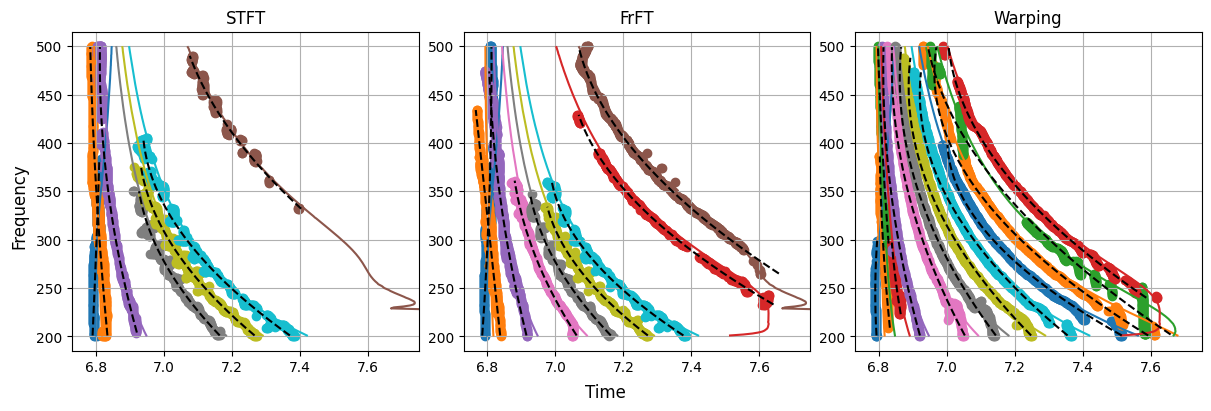

In [64]:
fig = plt.figure(layout="constrained")

titles = ['STFT', 'FrFT', 'Warping']

for indfig, name in enumerate(data):
    ax = fig.add_subplot(1,3,indfig +1)
    for ind, p in enumerate(data[name]['peaks_coordinates']):
        mode_no = data[name]['mode_nos'][ind]
        color = f"C{mode_no}"
        ax.scatter(p[:,1], p[:,0], c=color)
        ax.plot(at_reference[mode_no], f_Vg, c=color)

    ax.set_xlim([6.73, 7.75])
    ax.plot(atimes[name].T, f_Vg, 'k--')
    ax.grid()
    ax.set_title(titles[indfig])
    
    

fig.supxlabel('Time')
fig.supylabel('Frequency')

fig.set_size_inches([12,4])

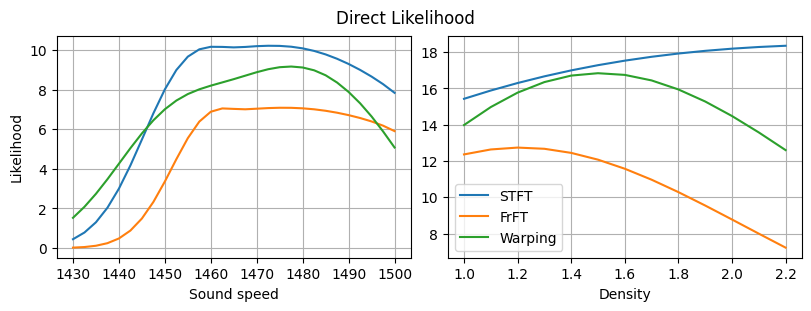

In [75]:
fig, (ax, ax_rho) = plt.subplots(1,2,layout="constrained")

for name in results:
    ax.plot(c, np.exp(results[name]['likelihood']).sum(0), label=name)
    ax_rho.plot(rho, np.exp(results[name]['likelihood']).sum(1), label=name)
    
ax.grid()
ax.set_xlabel("Sound speed")
ax.set_ylabel("Likelihood")

ax_rho.grid()
ax_rho.set_xlabel("Density")

ax_rho.legend()

fig.suptitle('Direct Likelihood')
fig.set_size_inches([8,3])
    

In [ ]:
for name in atimes:
    delta_atimes = ai.calculate_deltas(atimes[name])
    print(np.isnan(delta_atimes).sum()/np.prod(delta_atimes.shape)*100)

In [261]:
Vg.shape

(13, 29, 17, 299)